# 04 Pay: keywords and client countries

This notebook examines how words in job titles relate to offered pay and how hourly offers differ across client countries. Hourly rates and fixed-price budgets stay separate because they represent different types of pay.

| Field | Value |
|---|---|
| **Purpose** | Which title words go with higher or lower pay, and what hourly rates clients in different countries offer |
| **Assignment requirement** | **Task 1** (keyword-salary correlation) and **Task 4** (hourly rates by country, interactive map) |
| **Inputs** | `pay_keywords_hourly.csv`, `pay_keywords_budget.csv`, `pay_keyword_sensitivity.csv`, `pay_countries.csv`, `pay_country_sensitivity.csv`, `pay_prediction.csv` (all from the pipeline's `pay` step), `jobs_clean.parquet`, `job_categories.parquet` |
| **Outputs** | None; the tables above are reused by the database, the API and the dashboard |
| **Build identity** | Printed by the first code cell |

## Pay definitions

- For hourly jobs, pay is the midpoint of the complete hourly range stated by the client.
- Fixed-price jobs use the total budget stated for the whole job and are analysed separately from hourly jobs.
- `country` refers to the client's country, not the freelancer's location.
- The results show associations in the data, not cause and effect.

### Why use log pay?

- Pay values have a long right tail, with a small number of very large offers. The models therefore use the natural log of pay so the wide range of values is easier to handle.
- A model coefficient is converted back to a percentage difference using `(exp(b) - 1) × 100`. For example, `b = 0.5` represents about a 64.9% difference.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261011T132714Z-e537465460
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 54 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"   # interactive in JupyterLab, small notebook file
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)

keywords = project.read_csv("pay_keywords_hourly.csv")
budget_keywords = project.read_csv("pay_keywords_budget.csv")
sensitivity = project.read_csv("pay_keyword_sensitivity.csv")
countries = project.read_csv("pay_countries.csv", keep_default_na=False, na_values=[""])
country_sensitivity = project.read_csv("pay_country_sensitivity.csv")
prediction = project.read_csv("pay_prediction.csv")
rules = project.settings.section("pay")

jobs = project.read_parquet("jobs_clean.parquet", columns=[
    "row_id", "country", "title_key", "hourly_mid", "budget", "eligible_for_hourly_rate_analysis", "eligible_for_budget_analysis"])
hourly = jobs[jobs["eligible_for_hourly_rate_analysis"]]

def show_p(table):
    """Display copy: adjusted p-values below 0.001 shown as <0.001 (the stored values are unchanged)."""
    shown = table.copy()
    for column in [c for c in shown.columns if c.endswith("p_fdr")]:
        shown[column] = shown[column].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
    return shown


LAYER_NAMES = {"raw": "raw", "country": "same country", "country_category": "same country + category"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Hourly jobs with a complete rate: {len(hourly):,}; median ${hourly['hourly_mid'].median():.2f}/hour")

Hourly jobs with a complete rate: 98,775; median $22.50/hour


## 1. Task 1: Which title words are linked with higher or lower hourly offers?

### 1.1 Keywords included in the analysis

A keyword can be one word or a two-word phrase from `title_key`. Common stop words are removed, while technical terms such as C++ and C# stay intact. Two-word phrases are counted only when the words appear next to each other in the title.

Each keyword is counted once per job, even if it appears more than once in the same title.

A keyword is included only when it appears in:

- at least 300 hourly jobs with a complete stated rate range;
- at least 100 distinct `title_key` values.

These limits keep the analysis from relying on a small number of jobs or one heavily repeated title.

To avoid measuring almost the same signal twice, a single word is removed when at least 80% of its jobs also contain a retained two-word phrase using that word.

In [3]:
print(f"Keywords tested (hourly): {len(keywords)}, of which two-word phrases: {(keywords['keyword'].str.contains(' ')).sum()}")
print(f"Smallest support: {keywords['jobs'].min()} jobs, {keywords['title_keys'].min()} distinct titles")
keywords.sort_values("jobs", ascending=False)[["keyword", "jobs", "title_keys", "median_with", "median_without"]].head(12)

Keywords tested (hourly): 322, of which two-word phrases: 51
Smallest support: 300 jobs, 104 distinct titles


,keyword,jobs,title_keys,median_with,median_without
91,developer,7572,5912,25.0,22.5
114,expert,7041,6079,25.5,22.5
303,website,5770,5065,22.5,22.5
88,designer,5603,4560,25.0,22.5
258,specialist,4712,3660,19.5,22.5
87,design,4583,4031,25.0,22.5
290,video,4561,3676,20.0,22.5
171,marketing,4323,3567,20.0,22.5
168,manager,3879,2848,17.5,22.5
30,assistant,3860,2928,9.0,24.0


### 1.2 Three comparison layers

A keyword can appear to have a higher hourly offer because of the countries or job categories where it appears. To separate these effects, each keyword is compared in three ways:

- Raw comparison: compares jobs with the keyword against jobs without it.
- Country-adjusted comparison: compares the keyword within the same client country, so differences in country mix do not drive the result.
- Country-and-category-adjusted comparison: compares the keyword within the same client country and job function.

The third comparison is the most adjusted, but it is also narrower. Job category comes from the title itself, so controlling for category removes part of the title signal. For this reason, all three results are shown.
Each comparison uses log hourly offer. Uncertainty is clustered by `title_key` so repeated titles are not treated as fully independent evidence.
Because 322 keywords are tested, the Benjamini-Hochberg false discovery rate (FDR) is used at 5%. This controls the expected share of false positives among the keywords called significant.

In [4]:
significant = {layer: int((keywords[f"{layer}_p_fdr"] < 0.05).sum()) for layer in LAYER_NAMES}
flips = int(((keywords["raw_pct"] > 0) != (keywords["country_category_pct"] > 0)).sum())
pd.Series({**{f"significant at FDR 5% ({name})": n for name, n in
              zip(LAYER_NAMES.values(), significant.values())},
           "keywords whose sign differs between raw and same country + category": flips}).to_frame("keywords")

,keywords
significant at FDR 5% (raw),244
significant at FDR 5% (same country),243
significant at FDR 5% (same country + category),206
keywords whose sign differs between raw and same country + category,39


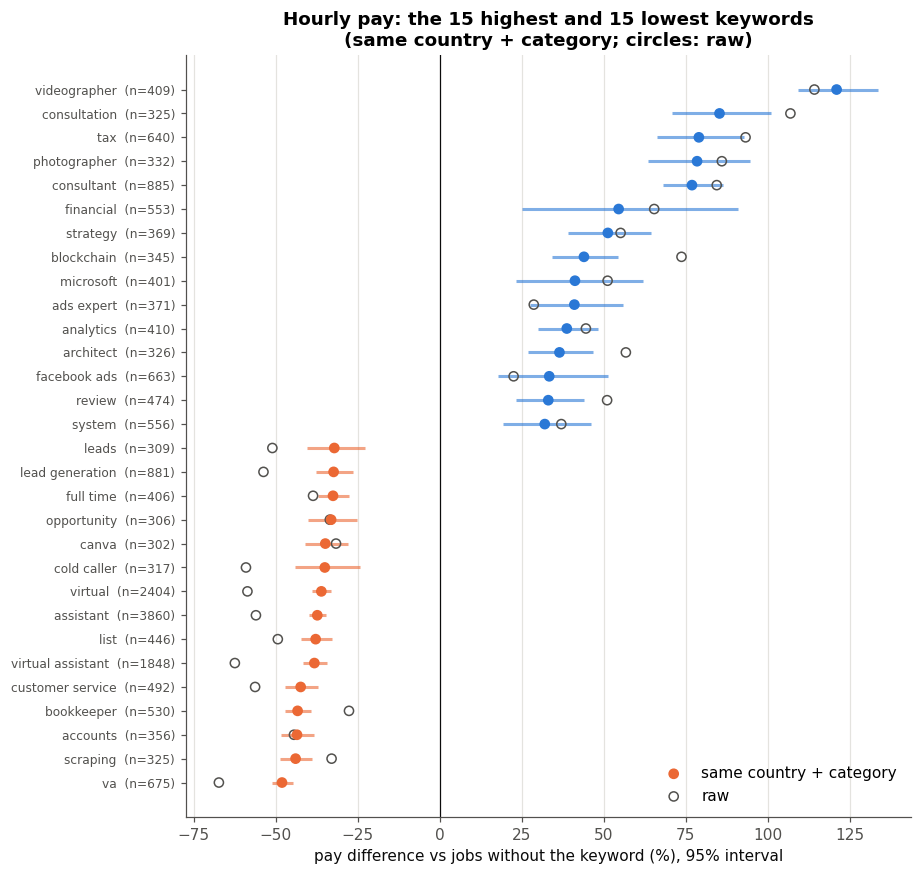

In [5]:
def forest(table, layer, title, n=15):
    top = table.nlargest(n, f"{layer}_pct")
    bottom = table.nsmallest(n, f"{layer}_pct")
    show = pd.concat([bottom, top]).drop_duplicates("keyword").sort_values(f"{layer}_pct")
    fig, ax = plt.subplots(figsize=(8.5, 9))
    y = np.arange(len(show))
    colors = [BLUE if v > 0 else ORANGE for v in show[f"{layer}_pct"]]
    ax.hlines(y, show[f"{layer}_low_pct"], show[f"{layer}_high_pct"], color=colors, lw=2, alpha=0.6)
    ax.scatter(show[f"{layer}_pct"], y, color=colors, zorder=3, label=LAYER_NAMES[layer])
    ax.scatter(show["raw_pct"], y, facecolors="none", edgecolors=MUTED, zorder=2, label="raw")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{k}  (n={j})" for k, j in zip(show["keyword"], show["jobs"])], fontsize=8)
    ax.set_xlabel("pay difference vs jobs without the keyword (%), 95% interval")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.show()

forest(keywords, "country_category", "Hourly pay: the 15 highest and 15 lowest keywords\n(same country + category; circles: raw)")

In [6]:
columns = ["keyword", "jobs", "median_with", "raw_pct", "country_pct", "country_category_pct",
           "country_category_low_pct", "country_category_high_pct", "country_category_p_fdr"]
print("Highest (same country + category):")
display(show_p(keywords.nlargest(10, "country_category_pct")[columns]).round(1))
print("Lowest (same country + category):")
show_p(keywords.nsmallest(10, "country_category_pct")[columns]).round(1)

Highest (same country + category):


,keyword,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
293,videographer,409,42.5,114.3,110.7,121.1,109.2,133.6,<0.001
64,consultation,325,47.5,107.0,104.5,85.3,70.8,101.2,<0.001
266,tax,640,50.0,93.3,86.3,79.1,66.2,92.8,<0.001
204,photographer,332,37.5,86.1,85.9,78.5,63.6,94.7,<0.001
63,consultant,885,40.0,84.5,84.0,76.9,68.0,86.4,<0.001
120,financial,553,37.5,65.4,63.8,54.6,25.2,90.9,<0.001
263,strategy,369,35.5,55.2,53.7,51.3,39.3,64.4,<0.001
37,blockchain,345,37.5,73.7,72.0,44.0,34.3,54.4,<0.001
181,microsoft,401,32.5,51.2,48.9,41.3,23.2,62.0,<0.001
10,ads expert,371,32.5,28.7,28.8,41.1,27.7,55.9,<0.001


Lowest (same country + category):


,keyword,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
289,va,675,6.5,-67.3,-67.2,-48.1,-51.2,-44.8,<0.001
234,scraping,325,16.5,-32.9,-33.2,-43.9,-48.6,-38.8,<0.001
5,accounts,356,9.0,-44.4,-42.2,-43.5,-48.4,-38.2,<0.001
40,bookkeeper,530,15.0,-27.6,-29.6,-43.3,-47.1,-39.2,<0.001
82,customer service,492,8.5,-56.3,-56.5,-42.4,-47.1,-37.2,<0.001
296,virtual assistant,1848,7.5,-62.4,-63.0,-38.2,-41.7,-34.5,<0.001
162,list,446,10.0,-49.3,-49.8,-37.8,-42.4,-32.9,<0.001
30,assistant,3860,9.0,-56.0,-57.0,-37.3,-39.9,-34.7,<0.001
295,virtual,2404,7.5,-58.6,-59.2,-36.1,-39.0,-33.0,<0.001
58,cold caller,317,7.5,-59.1,-60.0,-35.0,-44.2,-24.4,<0.001


- The largest positive associations appear with titles containing words such as videographer, consultation, consultant, tax, photographer, financial and strategy. After adjusting for client country and job category, "consultant" is associated with about 77% higher hourly offers.
- The largest negative associations appear with terms such as "va", "scraping", "bookkeeper", "customer service", "virtual assistant", "list", "cold caller" and "canva". "Virtual assistant" is associated with about 38% lower hourly offers after adjustment.

### 1.3 How adjustment changes the result
Most keywords keep the same direction after adjustment, but the size of the association often changes. For some keywords, the direction also changes.

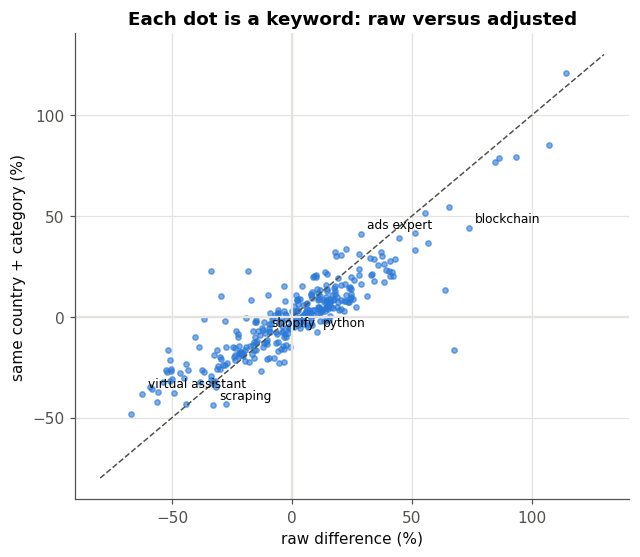

,jobs,raw_pct,country_pct,country_category_pct
keyword,,,,
python,824,10.2,9.9,-7.5
virtual assistant,1848,-62.4,-63.0,-38.2
blockchain,345,73.7,72.0,44.0
ads expert,371,28.7,28.8,41.1
scraping,325,-32.9,-33.2,-43.9
shopify,2323,-11.2,-10.1,-7.9


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(keywords["raw_pct"], keywords["country_category_pct"], s=12, color=BLUE, alpha=0.6)
lim = [-80, 130]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.axhline(0, color=GRID)
ax.axvline(0, color=GRID)
for word in ["python", "virtual assistant", "blockchain", "ads expert", "scraping", "shopify"]:
    row = keywords.set_index("keyword").loc[word]
    ax.annotate(word, (row["raw_pct"], row["country_category_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("raw difference (%)")
ax.set_ylabel("same country + category (%)")
ax.set_title("Each dot is a keyword: raw versus adjusted")
plt.show()
keywords.set_index("keyword").loc[["python", "virtual assistant", "blockchain", "ads expert", "scraping", "shopify"],
                                  ["jobs", "raw_pct", "country_pct", "country_category_pct"]].round(1)

The dashed line shows where the raw and adjusted results would be the same. Points closer to zero after adjustment have a smaller association once country and job category are taken into account.

- "python" changes from about +10% in the raw comparison to -7.5% after country and category adjustment.
- "virtual assistant" changes from about -62% to -38%.
- "blockchain" changes from about +74% to +44%.
- "ads expert" changes from about +29% to +41%.

For most keywords shown here, adjusting for client country changes the result less than adjusting for job category.

### 1.4 Technology and tool names

In [8]:
tools = ["hubspot", "aws", "webflow", "react", "ios", "ai", "android", "figma", "php", "python",
         "shopify", "wordpress", "flutter", "seo", "excel", "canva"]
show_p(keywords.set_index("keyword").loc[[t for t in tools if t in set(keywords["keyword"])],
    ["jobs", "median_with", "raw_pct", "country_pct", "country_category_pct",
     "country_category_low_pct", "country_category_high_pct", "country_category_p_fdr"]].sort_values(
    "country_category_pct", ascending=False)).round(2)

,jobs,median_with,raw_pct,country_pct,country_category_pct,country_category_low_pct,country_category_high_pct,country_category_p_fdr
keyword,,,,,,,,
hubspot,404,30.0,37.43,34.11,30.03,22.67,37.83,<0.001
aws,449,32.5,40.98,40.68,19.96,13.17,27.16,<0.001
webflow,579,22.5,13.19,13.80,8.06,2.98,13.40,0.003
react,1098,25.0,11.06,11.71,4.95,0.88,9.19,0.027
ios,410,25.0,16.07,16.48,4.69,-2.31,12.20,0.246
ai,1700,27.5,19.38,18.96,3.18,-1.88,8.49,0.279
android,364,22.5,12.11,13.45,2.70,-4.28,10.19,0.526
figma,558,25.0,7.77,7.30,-0.66,-5.60,4.53,0.827
php,429,25.0,-0.47,0.60,-3.56,-9.03,2.23,0.279


- Among the tool and technology terms, HubSpot is associated with about 30% higher hourly offers and AWS with about 20% higher offers after adjusting for client country and job category.
- Shopify, WordPress and Flutter show smaller negative associations, around 8% to 13% lower. SEO, Excel and Canva show larger negative associations, around 19% to 35% lower.
- "AI" shows about +19% in the raw comparison, but the adjusted difference is small and not statistically significant.

### 1.5 How much do title words explain?
- The next comparison checks how much title information improves pay prediction beyond country and job category.
- The data is split by `title_key`, with 80% used for training and 20% for testing. The same title does not appear in both groups.
- MAE shows the average prediction error in hourly-offer units. R² shows how much variation the model explains.

In [9]:
prediction[["model", "test_jobs", "mae_usd", "median_abs_error_usd", "r2_log", "title_keys_shared_with_training"]].round(3)

,model,test_jobs,mae_usd,median_abs_error_usd,r2_log,title_keys_shared_with_training
0,median baseline,19469,16.831,10.000,-0.000,0
1,country + category,19469,15.961,9.235,0.109,0
2,country + category + title words,19469,14.797,8.399,0.260,0
3,title words only,19469,14.921,8.426,0.248,0


Client country and job category explain about 11% of the variation in hourly offers. Adding title words raises this to about 26%, while title words alone explain about 25%. Prediction error still remains large, with a median error of about USD 8 per hour.

Title words therefore contain useful information about offered pay, but they do not explain most of the variation.

### 1.6 Sensitivity checks

The keyword analysis is compared with four alternative versions:

- without flagged extreme rates;
- without possible reposts;
- using the lower end of the hourly range;
- using the upper end of the hourly range.

These checks show whether the main keyword results remain stable when reasonable analysis choices change.

In [10]:
wide = sensitivity[sensitivity["layer"] == "country_category"].pivot(index="keyword", columns="variant", values="pct")
stability = pd.DataFrame({
    "correlation with primary": wide.corrwith(wide["primary"]).round(3),
    "same direction as primary (%)": (100 * ((wide > 0).eq(wide["primary"] > 0, axis=0)).mean()).round(1),
}).drop(index="primary")
stability

,correlation with primary,same direction as primary (%)
variant,,
high_end_of_range,0.997,98.8
low_end_of_range,0.966,93.5
without_extreme_pay,0.996,99.1
without_possible_reposts,0.994,97.8


Keyword results remain stable across the sensitivity checks. Each alternative has a correlation of at least 0.97 with the primary results, and at least 93% of keywords keep the same direction. Using the lower end of the hourly range changes the results the most.

### 1.7 Fixed-price budgets
Fixed-price budgets represent the total amount offered for a whole job, so they stay separate from hourly offers.
The same three comparison layers are used: raw, country-adjusted, and country-and-category-adjusted.

In [11]:
print(f"Budget keywords tested: {len(budget_keywords)}; significant at FDR 5% (same country + category): "
      f"{int((budget_keywords['country_category_p_fdr'] < 0.05).sum())}")
cols = ["keyword", "jobs", "median_with", "raw_pct", "country_category_pct", "country_category_p_fdr"]
display(show_p(budget_keywords.nlargest(8, "country_category_pct")[cols]).round(1))
display(show_p(budget_keywords.nsmallest(8, "country_category_pct")[cols]).round(1))
expensify = jobs[jobs["eligible_for_budget_analysis"] & jobs["title_key"].str.contains(r"\bexpensify\b", na=False)]
print(f"Budget postings with 'expensify' in the title: {len(expensify)}; "
      f"budget exactly USD 500: {int((expensify['budget'] == 500).sum())}")

Budget keywords tested: 340; significant at FDR 5% (same country + category): 240


,keyword,jobs,median_with,raw_pct,country_category_pct,country_category_p_fdr
130,full time,384,700.0,532.5,529.3,<0.001
109,expensify,491,500.0,391.8,313.0,<0.001
237,saas,479,350.0,267.7,225.6,<0.001
9,500,537,500.0,278.1,225.5,<0.001
129,full stack,632,300.0,248.4,210.9,<0.001
104,engineer,646,300.0,266.4,194.2,<0.001
208,platform,693,300.0,179.4,189.4,<0.001
235,romance,313,500.0,201.6,187.8,<0.001


,keyword,jobs,median_with,raw_pct,country_category_pct,country_category_p_fdr
156,issue,318,30.0,-64.7,-68.6,<0.001
121,fix,1040,30.0,-63.8,-68.2,<0.001
222,quick,722,25.0,-67.6,-66.3,<0.001
264,speakers,515,10.0,-85.0,-65.1,<0.001
164,lead generation,954,50.0,-35.3,-64.7,<0.001
98,edit,851,25.0,-65.7,-61.6,<0.001
279,test,409,25.0,-61.9,-60.1,<0.001
168,list,812,50.0,-53.2,-59.2,<0.001


Budget postings with 'expensify' in the title: 491; budget exactly USD 500: 442


Fixed-price budgets also vary with title words. Terms such as "full time", "SaaS", "platform", "full stack" and "engineer" are associated with higher stated budgets, while terms such as "fix", "issue", "quick", "edit" and "test" are associated with lower budgets.

Two of the highest budget keywords, "expensify" and "500", appear in a series of 491 bug-fix postings with titles such as "[$500] Tapping on Workspace avatar, app crashes #36834 - Expensify". Of these, 442 have a budget of exactly USD 500. The word "500" repeats the budget already stated in the title, so its association with budget size is partly circular. These results are specific to this repeated posting pattern and may not describe the wider market.

Fixed-price budgets remain separate from hourly offers because a budget is the total amount stated for a job, while an hourly offer is a rate per hour.

## 2. Task 4: Hourly offers by client country

### 2.1 Country comparison
Only countries with at least 30 hourly jobs with a complete stated rate range are included.

For each country, the analysis reports:

- the median hourly offer and the middle 50% of values;
- a 95% interval around the median;
- the mean hourly offer with its 95% interval. The brief asks for average rates; the median stays the main measure because a few very high offers pull the mean up;
- a category-adjusted index that compares the country's hourly offers with the overall average for a similar mix of job categories.

For the adjusted index, a value of +20% means hourly offers are about 20% higher than the overall average after accounting for job-category mix.

In [12]:
print(f"Countries with at least {rules['min_country_jobs']} rated jobs: {len(countries)}; "
      f"they cover {100 * countries['jobs'].sum() / len(hourly):.1f}% of rated jobs")
display(countries[["country", "jobs", "median_rate", "median_low", "median_high", "p25_rate", "p75_rate",
           "mean_rate", "mean_ci_low", "mean_ci_high", "adjusted_index_pct", "adjusted_low_pct", "adjusted_high_pct"]].head(20).round(2))
print("Smaller markets named in the findings:")
countries.set_index("country").loc[["South Korea", "Japan", "Taiwan"],
    ["jobs", "median_rate", "mean_rate", "adjusted_index_pct", "adjusted_low_pct", "adjusted_high_pct"]].round(2)

Countries with at least 30 rated jobs: 91; they cover 97.3% of rated jobs


,country,jobs,median_rate,median_low,median_high,p25_rate,p75_rate,mean_rate,mean_ci_low,mean_ci_high,adjusted_index_pct,adjusted_low_pct,adjusted_high_pct
0,United States,46620,25.0,25.0,25.00,15.00,40.00,32.58,32.04,33.20,8.71,8.03,9.35
1,United Kingdom,8113,22.5,22.5,24.00,15.00,35.00,29.49,28.68,30.40,1.82,0.01,4.29
2,Australia,5682,21.0,20.0,22.50,12.50,31.50,24.46,23.94,24.99,-12.13,-13.76,-10.45
3,Canada,5054,22.5,21.0,22.50,12.50,32.50,26.90,25.94,27.93,-6.47,-8.53,-4.37
4,India,4337,20.0,18.0,20.00,12.50,27.50,23.68,22.79,24.71,-20.63,-22.47,-18.78
5,Germany,2022,24.0,22.5,25.00,15.00,35.00,27.66,26.78,28.54,0.74,-1.80,3.17
6,Netherlands,1554,20.0,20.0,20.00,11.12,29.50,23.83,22.50,25.31,-16.20,-19.10,-13.17
7,Pakistan,1379,20.0,17.5,20.00,12.50,27.25,24.98,23.38,26.91,-15.29,-19.38,-11.76
8,United Arab Emirates,1227,22.5,22.5,22.50,12.50,32.50,26.99,25.33,29.05,-5.98,-9.88,-1.07
9,France,1213,21.0,20.0,22.50,12.50,30.00,26.08,24.44,27.88,-12.43,-15.76,-8.99


Smaller markets named in the findings:


,jobs,median_rate,mean_rate,adjusted_index_pct,adjusted_low_pct,adjusted_high_pct
country,,,,,,
South Korea,270,10.0,15.44,-48.10,-54.75,-37.80
Japan,246,15.0,21.99,-28.34,-36.22,-18.99
Taiwan,53,15.0,15.96,-36.41,-45.92,-26.36


### Narrow median intervals

Many hourly offers use round values such as USD 15, 20 and 25 per hour. In countries with many jobs, several offers can therefore share the same value. During bootstrap resampling, the median may stay unchanged, which can produce a very narrow interval or even a single value. This reflects the distribution of the observed offers rather than a calculation problem.

### 2.2 Interactive map

The map shows each country's median hourly offer, middle 50% of values, number of eligible jobs and category-adjusted index. Countries with fewer than 30 eligible hourly jobs are shown in grey and are not included in the ranked comparison.

The interactive map is intended for viewing in JupyterLab or the running dashboard. GitHub may not display the interactive version. The chart below shows the same country median comparison for the 30 countries with the most rated hourly jobs.

In [13]:
mapped = countries[countries["iso3"].notna() & (countries["iso3"] != "")]
missing_code = sorted(set(countries["country"]) - set(mapped["country"]))
print(f"Countries without a map code: {missing_code if missing_code else 'none'}")
hover = [f"<b>{c}</b><br>median ${m:.2f}/h<br>mean ${avg:.2f}/h<br>middle half ${a:.2f} to ${b:.2f}<br>jobs: {n:,}<br>"
         f"category-adjusted index: {i:+.0f}%" for c, m, avg, a, b, n, i in
         zip(mapped["country"], mapped["median_rate"], mapped["mean_rate"], mapped["p25_rate"], mapped["p75_rate"],
             mapped["jobs"], mapped["adjusted_index_pct"])]
figure = go.Figure(go.Choropleth(
    locations=mapped["iso3"], z=mapped["median_rate"], text=hover, hoverinfo="text",
    colorscale="Blues", marker_line_color="white", marker_line_width=0.4,
    colorbar_title="median $/h",
))
figure.update_layout(title="Median hourly rate offered by clients, by client country (30+ rated jobs)",
                     geo=dict(showframe=False, projection=dict(type="natural earth")),
                     margin=dict(l=0, r=0, t=50, b=0), height=480)
figure.show()

Countries without a map code: none


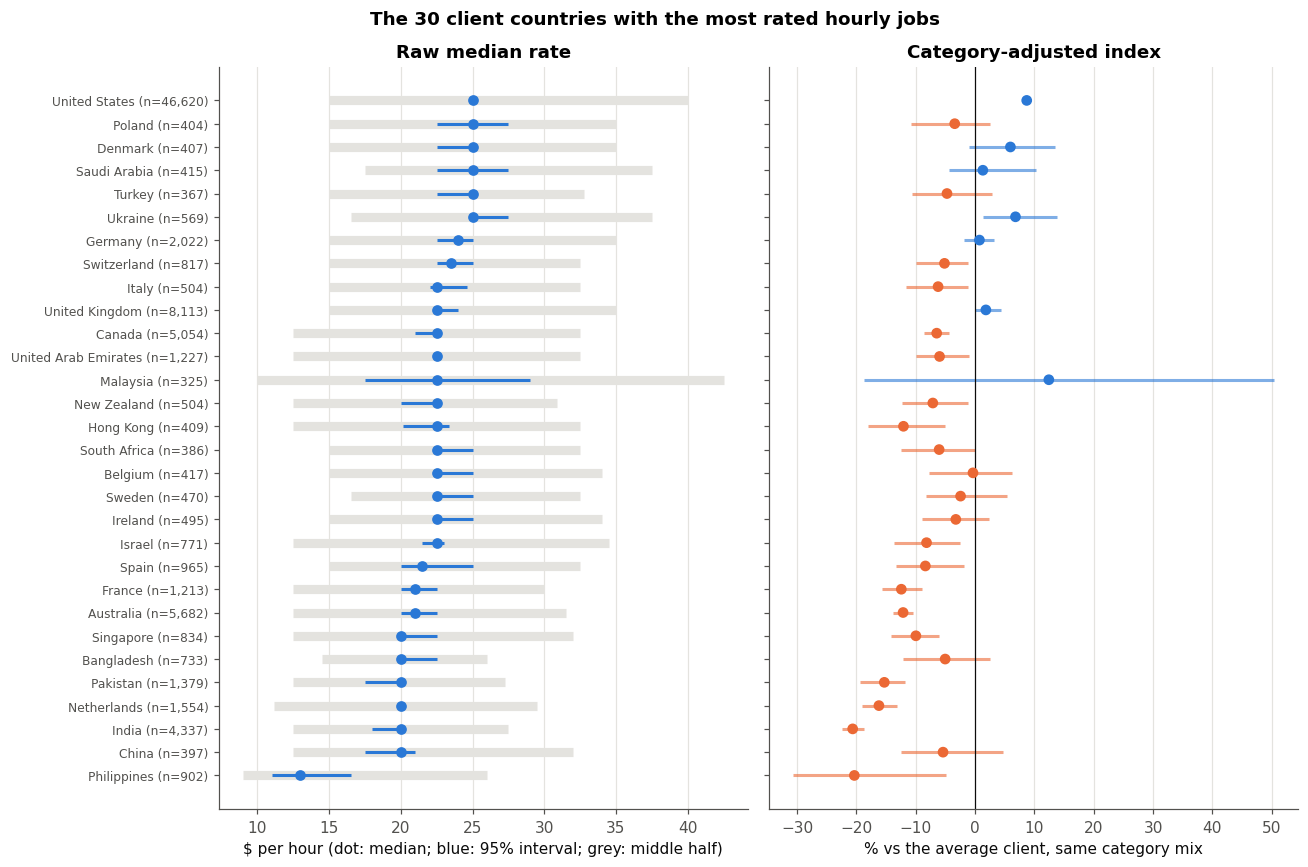

In [14]:
big = countries.nlargest(30, "jobs").sort_values("median_rate")
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
y = np.arange(len(big))
axes[0].hlines(y, big["p25_rate"], big["p75_rate"], color=GRID, lw=6)
axes[0].hlines(y, big["median_low"], big["median_high"], color=BLUE, lw=2)
axes[0].scatter(big["median_rate"], y, color=BLUE, zorder=3)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{c} (n={n:,})" for c, n in zip(big["country"], big["jobs"])], fontsize=8)
axes[0].set_xlabel("$ per hour (dot: median; blue: 95% interval; grey: middle half)")
axes[0].set_title("Raw median rate")
colors = [BLUE if v >= 0 else ORANGE for v in big["adjusted_index_pct"]]
axes[1].hlines(y, big["adjusted_low_pct"], big["adjusted_high_pct"], color=colors, lw=2, alpha=0.6)
axes[1].scatter(big["adjusted_index_pct"], y, color=colors, zorder=3)
axes[1].axvline(0, color=INK, lw=0.8)
axes[1].set_xlabel("% vs the average client, same category mix")
axes[1].set_title("Category-adjusted index")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("The 30 client countries with the most rated hourly jobs", fontweight="bold")
fig.tight_layout()
plt.show()

- United States clients have a median hourly offer of USD 25 and an adjusted index of about +9%.
- The United Kingdom, Germany and Switzerland are close to the overall adjusted average.
- India has a median of about USD 20 per hour and the Philippines about USD 13 per hour. After adjusting for job-category mix, both are about 20% below the overall average.
- Australia has a median hourly offer of about USD 21 per hour, but its adjusted index is about 12% below the overall average.
- South Korea, Japan and Taiwan have lower adjusted indexes, around 28% to 48% below the overall average, with wider uncertainty intervals.
- The mean is above the median in 89 of 91 countries, because a few very high offers pull it up. It also ranks countries differently (rank correlation 0.57 with the median). For example, the Philippines has a median of USD 13 but a mean of about USD 31 (95% interval USD 22 to 40). This is why the median stays the main measure.

The spread within countries is wide, so client country does not explain all of the variation in hourly offers.

### 2.3 Country sensitivity checks

In [15]:
wide_c = country_sensitivity.pivot(index="country", columns="variant", values="median_rate")
order = countries.nlargest(10, "jobs")["country"]
display(wide_c.loc[order, ["primary", "without_extreme_pay", "without_possible_reposts", "low_end_of_range", "high_end_of_range"]])
print("Mean hourly offer, with and without flagged extreme rates:")
wide_mean = country_sensitivity.pivot(index="country", columns="variant", values="mean_rate")
wide_mean.loc[order, ["primary", "without_extreme_pay"]].round(2)

variant,primary,without_extreme_pay,without_possible_reposts,low_end_of_range,high_end_of_range
country,,,,,
United States,25.0,25.0,25.0,15.0,35.0
United Kingdom,22.5,22.5,22.5,12.0,30.0
Australia,21.0,20.5,21.0,12.0,30.0
Canada,22.5,22.5,22.5,13.0,30.0
India,20.0,19.5,20.0,10.0,25.0
Germany,24.0,24.0,24.5,15.0,35.0
Netherlands,20.0,20.0,20.0,10.0,30.0
Pakistan,20.0,20.0,20.0,10.0,26.0
United Arab Emirates,22.5,22.5,22.5,13.0,30.0


Mean hourly offer, with and without flagged extreme rates:


variant,primary,without_extreme_pay
country,,
United States,32.58,31.46
United Kingdom,29.49,28.66
Australia,24.46,24.24
Canada,26.90,26.00
India,23.68,22.64
Germany,27.66,27.66
Netherlands,23.83,23.28
Pakistan,24.98,24.01
United Arab Emirates,26.99,26.40


In [16]:
rank_corr = wide_c.rank().corr(method="pearson")["primary"].drop("primary").round(3)
rank_corr.to_frame("rank correlation with primary (all countries)")

,rank correlation with primary (all countries)
variant,
high_end_of_range,0.900
low_end_of_range,0.686
without_extreme_pay,0.990
without_possible_reposts,0.964


Finding. Removing flagged extreme rates or possible reposts leaves the country rankings almost unchanged, with rank correlations of at least 0.96. Using the high end of the hourly range gives a similar ranking, with a correlation of 0.90. Using the low end changes the ranking more, with a correlation of 0.69.

Among the 20 countries with the most rated hourly jobs, the United States and Ukraine share the highest median hourly offer at USD 25 in the main analysis. Small differences between countries should not be overinterpreted, because the lower end of the hourly range changes the rankings more.

## 3. Summary

- 322 title keywords meet the support rules, and 206 of them (64%) remain significant after adjusting for client country and job category at FDR 5%.
- Title words add useful information about hourly offers. Explained variation rises from about 11% with country and category to about 26% when title words are added.
- Some keyword associations change after adjustment, showing that country and job-category mix matter.
- The main keyword results remain stable across the sensitivity checks.
- 91 client countries have at least 30 hourly jobs with a complete stated rate range.
- United States clients have a median hourly offer of USD 25, a mean of about USD 32.6 (95% interval USD 32.0 to 33.2) and an adjusted index of about +9%.
- Country adjustment changes some results, so both the raw median and the category-adjusted view are useful.

### Limitations

- The results show associations, not causes.
- Hourly offers are the rates stated by clients, not final freelancer earnings.
- Hourly-pay analysis only includes jobs with enough stated rate information.
- Category-based adjustment carries the uncertainty of the job-category system, especially for categories with lower recall.

## 4. Claims check

In [17]:
kw = keywords.set_index("keyword")
ct = countries.set_index("country")
pred = prediction.set_index("model")
claims = {
    "322 keywords": len(keywords) == 322,
    "about two-thirds significant within country+category": 0.6 <= significant["country_category"] / len(keywords) <= 0.7,
    "consultant about +77%": round(kw.loc["consultant", "country_category_pct"]) == 77,
    "virtual assistant about -38%": round(kw.loc["virtual assistant", "country_category_pct"]) == -38,
    "python +10% raw, -7.5% within": (round(kw.loc["python", "raw_pct"]) == 10
                                      and round(kw.loc["python", "country_category_pct"], 1) == -7.5),
    "virtual assistant -62% raw": round(kw.loc["virtual assistant", "raw_pct"]) == -62,
    "blockchain +74% -> +44%": (round(kw.loc["blockchain", "raw_pct"]), round(kw.loc["blockchain", "country_category_pct"])) == (74, 44),
    "ads expert +29% -> +41%": (round(kw.loc["ads expert", "raw_pct"]), round(kw.loc["ads expert", "country_category_pct"])) == (29, 41),
    "hubspot +30%, aws +20%": (round(kw.loc["hubspot", "country_category_pct"]), round(kw.loc["aws", "country_category_pct"])) == (30, 20),
    "shopify/wordpress/flutter -8% to -13%": all(-13.5 <= kw.loc[w, "country_category_pct"] <= -7.5
                                                for w in ["shopify", "wordpress", "flutter"]),
    "seo/excel/canva -19% to -35%": all(-35.5 <= kw.loc[w, "country_category_pct"] <= -19 for w in ["seo", "excel", "canva"]),
    "ai +19% raw, adjusted not significant": (round(kw.loc["ai", "raw_pct"]) == 19 and kw.loc["ai", "country_category_p_fdr"] > 0.05),
    "controls explain about 11%": round(100 * pred.loc["country + category", "r2_log"]) == 11,
    "with title words about 26%": round(100 * pred.loc["country + category + title words", "r2_log"]) == 26,
    "title words alone about 25%": round(100 * pred.loc["title words only", "r2_log"]) == 25,
    "median error about USD 8": round(pred.loc["country + category + title words", "median_abs_error_usd"]) == 8,
    "no shared title keys in the split": int(pred["title_keys_shared_with_training"].max()) == 0,
    "sensitivity correlations >= 0.97": bool((stability["correlation with primary"] >= 0.965).all()),
    "sensitivity same direction >= 93%": bool((stability["same direction as primary (%)"] >= 93).all()),
    "91 countries": len(countries) == 91,
    "US median USD 25, about +9%": (ct.loc["United States", "median_rate"] == 25 and round(ct.loc["United States", "adjusted_index_pct"]) == 9),
    "US median interval is exactly USD 25": ct.loc["United States", "median_low"] == ct.loc["United States", "median_high"] == 25,
    "India USD 20 and Philippines USD 13, about -20%": (ct.loc["India", "median_rate"] == 20 and ct.loc["Philippines", "median_rate"] == 13
                                                 and all(-22 <= ct.loc[c, "adjusted_index_pct"] <= -19 for c in ["India", "Philippines"])),
    "Australia USD 21, about -12%": ct.loc["Australia", "median_rate"] == 21 and round(ct.loc["Australia", "adjusted_index_pct"]) == -12,
    "UK, Germany, Switzerland close to average": all(abs(ct.loc[c, "adjusted_index_pct"]) < 6
                                                     for c in ["United Kingdom", "Germany", "Switzerland"]),
    "Korea/Japan/Taiwan -28% to -48%": all(-48.5 <= ct.loc[c, "adjusted_index_pct"] <= -28
                                           for c in ["South Korea", "Japan", "Taiwan"]),
    "extremes/reposts rank correlation >= 0.96": bool(rank_corr[["without_extreme_pay", "without_possible_reposts"]].min() >= 0.96),
    "mean above median in 89 of 91 countries": int((countries["mean_rate"] > countries["median_rate"]).sum()) == 89,
    "mean and median rank correlation about 0.57": round(countries[["mean_rate", "median_rate"]].corr(method="spearman").iloc[0, 1], 2) == 0.57,
    "US mean about USD 32.6 (32.0 to 33.2), 31.5 without extremes": (
        round(ct.loc["United States", "mean_rate"], 1) == 32.6 and round(ct.loc["United States", "mean_ci_low"], 1) == 32.0
        and round(ct.loc["United States", "mean_ci_high"], 1) == 33.2 and round(wide_mean.loc["United States", "without_extreme_pay"], 1) == 31.5),
    "Philippines median USD 13, mean about USD 31 (22 to 40)": (
        ct.loc["Philippines", "median_rate"] == 13 and round(ct.loc["Philippines", "mean_rate"]) == 31
        and (round(ct.loc["Philippines", "mean_ci_low"]), round(ct.loc["Philippines", "mean_ci_high"])) == (22, 40)),
    "US and Ukraine share the highest median (USD 25) among the 20 largest": (
        set(countries.nlargest(20, "jobs").query("median_rate == median_rate.max()")["country"]) == {"United States", "Ukraine"}
        and countries.nlargest(20, "jobs")["median_rate"].max() == 25),
    "expensify: 491 budget postings, 442 at exactly USD 500": (
        int(budget_keywords.set_index("keyword").loc["expensify", "jobs"]) == len(expensify) == 491
        and int((expensify["budget"] == 500).sum()) == 442),
    "high end 0.90, low end 0.69": (round(rank_corr["high_end_of_range"], 2), round(rank_corr["low_end_of_range"], 2)) == (0.90, 0.69),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
322 keywords,True
about two-thirds significant within country+category,True
consultant about +77%,True
virtual assistant about -38%,True
"python +10% raw, -7.5% within",True
virtual assistant -62% raw,True
blockchain +74% -> +44%,True
ads expert +29% -> +41%,True
"hubspot +30%, aws +20%",True
shopify/wordpress/flutter -8% to -13%,True
